# Módulo 8 · Aprendizaje automático con imágenes de células sanguíneas

**Guía para estudiantes.**

En esta clase recorremos el flujo completo del aprendizaje automático sobre un mismo conjunto de imágenes: clasificar, diagnosticar el sobreajuste, reducir la dimensión y agrupar sin etiquetas. Como en el módulo 7, nadie escribe código desde cero: se **pide** al asistente, se **lee** lo que generó, se **ejecuta** y se **verifica**.

| Bloque | Producto |
|---|---|
| 1. Imágenes y primer clasificador | Matriz de confusión interpretada |
| 2. Árbol, bosque y sobreajuste | Tabla de modelos y curva por profundidad |
| 3. Redes neuronales y curva de pérdida | Curva de pérdida con la época de parada marcada |
| 4. PCA y ablación | Figura de PCA y tabla de ablación |
| 5. Agrupamiento con K-Means | Tablas de grupos frente a tipos celulares |
| Cierre | Elección justificada de un modelo |

**Cómo trabajar con este cuaderno**

- Cada bloque empieza con un **ejemplo resuelto**. Después vienen las **consignas**: dicen qué se espera, no cómo pedirlo. El prompt lo escribís vos.
- Si te trabás, abrí la pista **¿Te trabaste?** que hay debajo de cada consigna.
- Anotá el prompt que usaste en el espacio **Tu prompt**: sirve para revisar después qué funcionó.
- Las consignas de **verificación** piden comprobar un resultado antes de seguir. No las saltees. Con imágenes hay una regla más: **antes de confiar en un resultado, mirá imágenes reales.**

## Sobre los datos

Trabajamos con **BloodMNIST**: 17 092 imágenes de microscopía de células normales de sangre periférica, tomadas con un analizador automático (CellaVision DM96) en el laboratorio central del Hospital Clínic de Barcelona y clasificadas por patólogos clínicos expertos. Las personas donantes no tenían infecciones ni enfermedades hematológicas u oncológicas, y no estaban bajo tratamiento farmacológico al momento de la extracción.

Las imágenes originales miden 360 × 363 píxeles. MedMNIST, la colección que publica esta versión, las recortó y las redujo a **28 × 28 píxeles en color**: se pierde detalle, pero cada imagen ocupa poco y los modelos se entrenan en segundos en cualquier computadora.

**Los ocho tipos celulares**

| Etiqueta | Tipo celular | Qué es |
|---|---|---|
| 0 | basófilo | Granulocito poco frecuente, con gránulos grandes y oscuros que tapan el núcleo. Libera histamina en las reacciones alérgicas. |
| 1 | eosinófilo | Granulocito con gránulos que se tiñen de anaranjado y núcleo de dos lóbulos. Interviene en alergias y en la defensa contra parásitos. |
| 2 | eritroblasto | Precursor del glóbulo rojo que todavía conserva el núcleo. |
| 3 | granulocito inmaduro | Precursores del neutrófilo (promielocito, mielocito y metamielocito), agrupados en una sola clase. |
| 4 | linfocito | Célula chica con un núcleo redondo que ocupa casi todo el citoplasma. Es la base de la inmunidad adaptativa. |
| 5 | monocito | El leucocito más grande, con núcleo en forma de riñón. En los tejidos se transforma en macrófago. |
| 6 | neutrófilo | El granulocito más abundante, con núcleo segmentado en varios lóbulos. Es la primera defensa contra bacterias. |
| 7 | plaqueta | No es una célula sino un fragmento sin núcleo. Interviene en la coagulación. |

**Cómo están organizados los datos.**

- El archivo trae tres **particiones** ya armadas: entrenamiento (11 959 imágenes), validación (1712) y prueba (3421).
- Cada imagen es un arreglo de 28 × 28 × 3 números enteros entre 0 y 255: la intensidad de rojo, verde y azul en cada píxel.
- Los tipos celulares no están balanceados: en entrenamiento hay de 849 linfocitos a 2330 neutrófilos. Por eso usamos una **submuestra balanceada de 5000 imágenes** (625 de cada tipo) y medimos con **F1 macro**, que pesa igual a todos los tipos.

**Más información.**

- **Página de MedMNIST:** [medmnist.github.io](https://medmnist.github.io/)
- **Fuente original:** Acevedo, A. et al. (2020). A dataset of microscopic peripheral blood cell images for development of automatic recognition systems. *Data in Brief*, 30, 105474.
- **Colección:** Yang, J. et al. (2023). MedMNIST v2. *Scientific Data*, 10, 41.
- **Descripción detallada, licencia (CC BY 4.0) y cómo descargarlo:** [`data/README.md`](../data/README.md) en la carpeta del curso.

## 0. Configuración

Esta es la **única celda** que nombra al conjunto de datos y fija los parámetros de la clase. El resto del cuaderno usa estos nombres.

In [1]:
# === Configuración del conjunto de datos ===

# De dónde salen los datos (el mismo archivo en dos lugares)
RUTA_NPZ = "../data/bloodmnist.npz"  # copia en la carpeta del curso (herramientas/descargar_bloodmnist.py)
URL_DATOS = "https://zenodo.org/records/10519652/files/bloodmnist.npz?download=1"  # original publicado en Zenodo

# Qué hay dentro del archivo: para cada partición, las imágenes (variables de entrada)
# y las etiquetas (variable objetivo)
CLAVES = {
    "entrenamiento": ("train_images", "train_labels"),
    "validación": ("val_images", "val_labels"),
    "prueba": ("test_images", "test_labels"),
}

# Variable objetivo: el tipo celular, codificado de 0 a 7 en este orden
TIPOS_CELULARES = ["basófilo", "eosinófilo", "eritroblasto", "granulocito inmaduro",
                   "linfocito", "monocito", "neutrófilo", "plaqueta"]

# Bloque 1
IMAGENES_POR_TIPO = 625   # submuestra balanceada: 625 × 8 = 5000 imágenes de entrenamiento

# Bloque 2
PROFUNDIDADES = [1, 2, 3, 4, 6, 8, 10, 12, 15, 20]  # profundidades máximas del árbol

# Bloque 3
NEURONAS = (100,)   # una capa oculta de 100 neuronas
EPOCAS = 40         # pasadas completas por los datos de entrenamiento

# Bloque 4
COMPONENTES = [2, 10, 50, 200]  # cantidades de componentes principales para la ablación

# Bloque 5
TIPOS_CONTRASTADOS = ["linfocito", "monocito", "neutrófilo", "plaqueta"]
COMPONENTES_AGRUPAMIENTO = 50   # componentes principales sobre las que trabaja K-Means
K_MAXIMO = 10                   # mayor cantidad de grupos que se prueba

SEMILLA = 42  # semilla fija: los resultados se repiten en cada ejecución

In [2]:
# Librerías que usa el cuaderno (con sus versiones en requirements.txt)
import os
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (f1_score, classification_report, ConfusionMatrixDisplay,
                             log_loss, adjusted_rand_score, silhouette_score)
from sklearn.exceptions import ConvergenceWarning

# La red del bloque 3 se entrena a propósito pocas épocas; este aviso diría que no terminó de converger
warnings.filterwarnings("ignore", category=ConvergenceWarning)

## Bloque 1 · Imágenes y primer clasificador

**Producto:** una matriz de confusión interpretada.

Un clasificador no ve una célula: ve una **tabla de números**. El primer paso es convertir cada imagen en una fila de esa tabla.

**Ejemplo resuelto.** Carga de las tres particiones. Si el archivo no está en la carpeta del curso, se descarga una vez desde Zenodo.

In [3]:
# Si el archivo no está en la carpeta del curso, se descarga (35 MB, una sola vez)
if not os.path.exists(RUTA_NPZ):
    os.makedirs(os.path.dirname(RUTA_NPZ), exist_ok=True)
    urllib.request.urlretrieve(URL_DATOS, RUTA_NPZ)

archivo = np.load(RUTA_NPZ)
imagenes_completo = archivo[CLAVES["entrenamiento"][0]]
y_completo = archivo[CLAVES["entrenamiento"][1]].ravel()  # ravel: de columna a lista de etiquetas
imagenes_val = archivo[CLAVES["validación"][0]]
y_val = archivo[CLAVES["validación"][1]].ravel()
imagenes_prueba = archivo[CLAVES["prueba"][0]]
y_prueba = archivo[CLAVES["prueba"][1]].ravel()

print("Entrenamiento completo:", imagenes_completo.shape)
print("Validación:            ", imagenes_val.shape)
print("Prueba:                ", imagenes_prueba.shape)

Entrenamiento completo: (11959, 28, 28, 3)
Validación:             (1712, 28, 28, 3)
Prueba:                 (3421, 28, 28, 3)


**Ejemplo resuelto.** Submuestra balanceada: 625 imágenes de cada tipo celular, elegidas al azar con la semilla fija. Todos los modelos de la clase se entrenan con estas 5000 imágenes.

In [4]:
generador = np.random.default_rng(SEMILLA)
indices = []
for tipo in range(len(TIPOS_CELULARES)):
    indices_del_tipo = np.flatnonzero(y_completo == tipo)
    indices.extend(generador.choice(indices_del_tipo, IMAGENES_POR_TIPO, replace=False))
indices = generador.permutation(indices)  # se mezclan para que no queden ordenadas por tipo

imagenes_entr = imagenes_completo[indices]
y_entr = y_completo[indices]
print("Submuestra de entrenamiento:", imagenes_entr.shape)

Submuestra de entrenamiento: (5000, 28, 28, 3)


**Ejemplo resuelto.** Una función para mirar imágenes, que vamos a usar en toda la clase. Recibe una lista de imágenes y, si se quiere, un título para cada una.

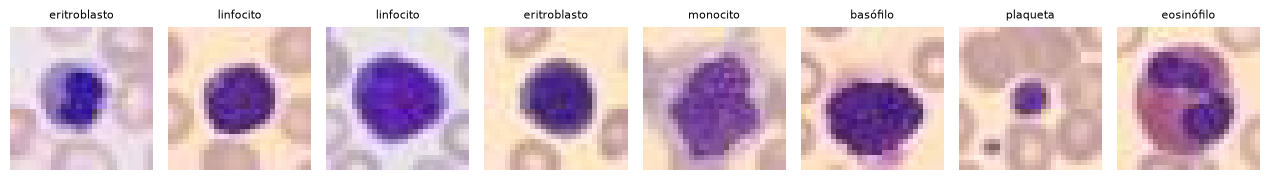

In [5]:
def mostrar_imagenes(imagenes, titulos=None, columnas=8, titulo_figura=None):
    """Muestra imágenes en una grilla, con un título opcional sobre cada una."""
    filas = int(np.ceil(len(imagenes) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(1.6 * columnas, 2.1 * filas), squeeze=False)
    for i, eje in enumerate(ejes.flat):
        eje.axis("off")
        if i < len(imagenes):
            if imagenes[i].ndim == 2:
                # Imagen en gris (un solo canal): escala fija de 0 a 255, sin estirar el contraste
                eje.imshow(imagenes[i], cmap="gray", vmin=0, vmax=255)
            else:
                eje.imshow(imagenes[i])
            if titulos is not None:
                eje.set_title(titulos[i], fontsize=8)
    if titulo_figura:
        fig.suptitle(titulo_figura)
    plt.tight_layout()
    plt.show()

mostrar_imagenes(imagenes_entr[:8], [TIPOS_CELULARES[t] for t in y_entr[:8]])

#### Consigna 1.1 · Conocer las células

Mostrá 6 imágenes de cada tipo celular de la submuestra de entrenamiento, con el nombre del tipo como título.

**Se espera:** una grilla de 8 filas (una por tipo celular) y 6 columnas. Antes de seguir, mirala con la tabla de tipos celulares de arriba: ¿reconocés el núcleo segmentado del neutrófilo, el núcleo redondo del linfocito, el tamaño chico de la plaqueta? ¿Qué tipos te parecen difíciles de distinguir a esta resolución?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Para cada tipo celular, buscá las primeras 6 imágenes cuya etiqueta en `y_entr` sea ese tipo. Juntá todas en una lista y pasala a `mostrar_imagenes` con `columnas=6`.

</details>

**Tu prompt:**

*...*

In [6]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 1.2 · Verificación: ¿quedó balanceada?

Contá cuántas imágenes de cada tipo celular hay en la submuestra de entrenamiento y en la partición de prueba.

**Se espera:** una tabla con 8 filas y dos columnas. En entrenamiento, 625 en cada fila (5000 en total). En prueba, los conteos reales del archivo, que no están balanceados (3421 en total).

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Contar cuántas veces aparece cada etiqueta es una operación común en NumPy y en pandas. Usá `TIPOS_CELULARES` como nombres de las filas.

</details>

**Tu prompt:**

*...*

In [7]:
# Pegá o escribí aquí el código que generó el asistente


**Ejemplo resuelto.** De imagen a tabla. Cada imagen de 28 × 28 píxeles con 3 canales se **aplana** en una fila de 28 × 28 × 3 = 2352 números, y se divide por 255 para que queden entre 0 y 1. Cada columna de la tabla es la intensidad de un color en un píxel.

Además preparamos una versión **estandarizada** de las tablas: cada columna con media 0 y desvío 1. Algunos modelos (la regresión logística, las redes) la necesitan; otros no, y lo vamos a ver a lo largo de la clase. El estandarizador aprende la media y el desvío **solo con los datos de entrenamiento** y después se aplica igual a validación y a prueba: si aprendiera de prueba, el modelo «espiaría» datos que no debe ver.

Por último, una lista `resultados` donde cada modelo va a anotar su F1. La usamos en el cierre.

In [8]:
def aplanar(imagenes):
    """Convierte imágenes de 28 × 28 × 3 en filas de 2352 valores entre 0 y 1."""
    return imagenes.reshape(len(imagenes), -1) / 255

X_entr = aplanar(imagenes_entr)
X_val = aplanar(imagenes_val)
X_prueba = aplanar(imagenes_prueba)
print("Tabla de entrenamiento:", X_entr.shape, "→ filas = imágenes, columnas = píxeles × canales")

# Versión estandarizada: media y desvío de cada columna calculados SOLO con entrenamiento
estandarizador = StandardScaler().fit(X_entr)
X_entr_est = estandarizador.transform(X_entr)
X_val_est = estandarizador.transform(X_val)
X_prueba_est = estandarizador.transform(X_prueba)

resultados = []  # cada modelo agrega aquí su F1 de entrenamiento y de prueba

Tabla de entrenamiento: (5000, 2352) → filas = imágenes, columnas = píxeles × canales


#### Consigna 1.3 · El primer clasificador

Entrená una **regresión logística** con la submuestra de entrenamiento estandarizada y evaluala en prueba.

**Se espera:**

- el F1 macro en entrenamiento y en prueba, con tres decimales;
- la **matriz de confusión** en prueba, con los nombres de los tipos celulares en los ejes;
- el resultado anotado en `resultados`.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

La regresión logística y la matriz de confusión están en scikit-learn. La regresión logística puede necesitar más iteraciones que las que trae por defecto. El F1 macro es el promedio del F1 de cada tipo celular.

</details>

**Tu prompt:**

*...*

In [9]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 1.4 · Mirar los errores

Mostrá 16 imágenes de prueba que la regresión logística clasificó mal, cada una con su tipo verdadero y el predicho.

**Se espera:** una grilla de 16 imágenes con títulos del estilo «verdadero → predicho». Mirándolas: ¿los errores son comprensibles (células que se parecen) o absurdos?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Las imágenes mal clasificadas son aquellas donde la predicción no coincide con `y_prueba`. Para que el título entre en la imagen, conviene usar nombres cortos o dos renglones.

</details>

**Tu prompt:**

*...*

In [10]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 1.5 · Verificación: el recall a mano

El **recall** de un tipo celular es la fracción de sus imágenes que el modelo reconoció. Elegí un tipo y calculá su recall **a mano** con los números de su fila en la matriz de confusión (aciertos sobre total de la fila). Después pedí el reporte de clasificación de scikit-learn y comparalo.

**Se espera:** el reporte con precisión, recall y F1 de cada tipo celular, y que tu cuenta coincida con su recall en los dos primeros decimales.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

scikit-learn tiene una función que arma un reporte de clasificación con las métricas de cada clase. Pedí que use los nombres de los tipos celulares.

</details>

**Tu prompt:**

*...*

In [11]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

## Bloque 2 · Árbol, bosque y sobreajuste

**Producto:** una tabla de modelos y la curva de F1 según la profundidad del árbol.

Un **árbol de decisión** clasifica con una serie de preguntas de sí o no («¿la intensidad de azul en este píxel es mayor que 0,6?»). Un **bosque aleatorio** entrena muchos árboles, cada uno con una parte distinta de los datos, y los hace votar.

Los árboles comparan cada columna con un umbral, así que **no necesitan estandarizar**: usamos `X_entr` tal como está.

**Ejemplo resuelto.** Un árbol sin límite de profundidad: crece hasta clasificar bien cada imagen de entrenamiento.

In [12]:
arbol = DecisionTreeClassifier(random_state=SEMILLA).fit(X_entr, y_entr)

f1_entr = f1_score(y_entr, arbol.predict(X_entr), average="macro")
f1_prueba = f1_score(y_prueba, arbol.predict(X_prueba), average="macro")
print(f"Profundidad alcanzada: {arbol.get_depth()} · hojas: {arbol.get_n_leaves()}")
print(f"F1 macro · entrenamiento: {f1_entr:.3f} · prueba: {f1_prueba:.3f}")
resultados.append({"modelo": "árbol sin límite", "F1 entrenamiento": f1_entr, "F1 prueba": f1_prueba})

Profundidad alcanzada: 21 · hojas: 700
F1 macro · entrenamiento: 1.000 · prueba: 0.574


#### Consigna 2.1 · Un bosque aleatorio

Entrená un bosque aleatorio de 100 árboles con la semilla de la configuración y armá una tabla que compare los tres modelos hasta ahora: regresión logística, árbol y bosque.

**Se espera:** una tabla con una fila por modelo y dos columnas, F1 en entrenamiento y en prueba, con tres decimales. ¿Qué modelo memoriza más? ¿Cuál generaliza mejor?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

scikit-learn tiene un bosque aleatorio para clasificación. La tabla se puede armar directamente desde la lista `resultados`.

</details>

**Tu prompt:**

*...*

In [13]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 2.2 · Sobreajuste según la profundidad

Igual que con el grado del polinomio en el módulo 7: para cada profundidad máxima de `PROFUNDIDADES`, entrená un árbol y medí su F1 en entrenamiento y en prueba.

**Se espera:** una tabla `tabla_profundidad` y un gráfico con dos curvas (entrenamiento y prueba) en función de la profundidad máxima.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Es un ciclo: para cada profundidad, un árbol nuevo con esa profundidad máxima. El parámetro del árbol que la limita se llama `max_depth`. Este ciclo tarda alrededor de un minuto.

</details>

**Tu prompt:**

*...*

In [14]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 2.3 · Verificación: ¿dónde deja de mejorar?

Mirando **solo el gráfico**, anotá la profundidad a partir de la cual el F1 de prueba deja de mejorar. Después pedí que se calcule desde la tabla.

**Se espera:** tu lectura del gráfico y la profundidad con mayor F1 de prueba según la tabla. Si no coinciden exactamente, ¿cuánto difieren los F1 de prueba entre esas profundidades?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Buscá la profundidad donde la curva de prueba tiene su máximo; pandas tiene una función que devuelve la posición del máximo de una columna.

</details>

**Tu prompt:**

*...*

In [15]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 2.4 · ¿Qué píxeles mira el bosque?

El bosque registra cuánto usó cada columna para decidir (su **importancia**). Como cada columna es un píxel de un canal, la importancia se puede volver a dibujar como una imagen de 28 × 28.

**Se espera:** una figura con dos paneles: la imagen promedio de la submuestra de entrenamiento y un mapa de calor de 28 × 28 con la importancia de cada píxel (sumando los tres canales). ¿Dónde se concentra la importancia? ¿Tiene sentido mirando las imágenes?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Las importancias del bosque son un arreglo de 2352 valores, en el mismo orden en que se aplanaron las imágenes: se pueden volver a dar forma de 28 × 28 × 3 y sumar sobre el último eje.

</details>

**Tu prompt:**

*...*

In [16]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

## Bloque 3 · Redes neuronales y curva de pérdida

**Producto:** la curva de pérdida con la época de parada marcada.

Una **red neuronal** como la del módulo 2: capas de neuronas que transforman los 2352 valores de entrada hasta dar una probabilidad para cada tipo celular. Se entrena por **épocas**: en cada época recorre todos los datos de entrenamiento y ajusta sus pesos para reducir la **pérdida**, una medida de cuán lejos están sus probabilidades de las respuestas correctas.

**Una tercera partición: validación.** En el bloque 2 elegimos la profundidad mirando el F1 de **prueba**. Eso es hacer un poco de trampa: si usamos prueba para tomar decisiones, deja de ser una medición independiente. Para decidir (cuándo parar, qué profundidad usar) se usa la partición de **validación**, y prueba se reserva para el informe final.

**Ejemplo resuelto.** Una red con una capa oculta de 100 neuronas, entrenada `EPOCAS` épocas con los datos estandarizados. La curva muestra la pérdida en entrenamiento, época a época.

F1 macro · entrenamiento: 1.000 · prueba: 0.793


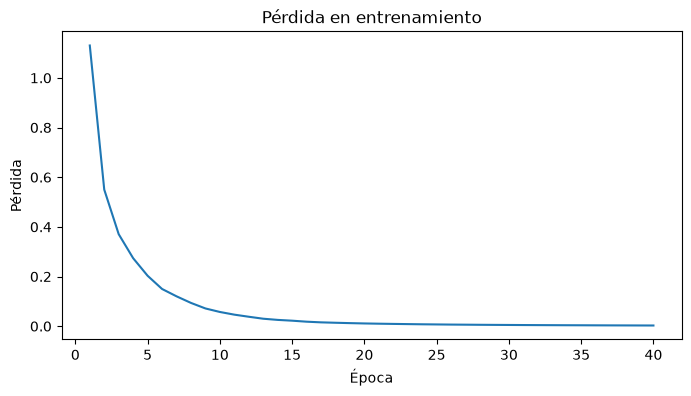

In [17]:
red = MLPClassifier(NEURONAS, max_iter=EPOCAS, random_state=SEMILLA).fit(X_entr_est, y_entr)

f1_entr = f1_score(y_entr, red.predict(X_entr_est), average="macro")
f1_prueba = f1_score(y_prueba, red.predict(X_prueba_est), average="macro")
print(f"F1 macro · entrenamiento: {f1_entr:.3f} · prueba: {f1_prueba:.3f}")
resultados.append({"modelo": f"red {NEURONAS}, {EPOCAS} épocas", "F1 entrenamiento": f1_entr, "F1 prueba": f1_prueba})

fig, eje = plt.subplots(figsize=(8, 4))
eje.plot(range(1, len(red.loss_curve_) + 1), red.loss_curve_)
eje.set(title="Pérdida en entrenamiento", xlabel="Época", ylabel="Pérdida")
plt.show()

#### Consigna 3.1 · La pérdida en validación

La curva del ejemplo solo dice cuánto aprendió la red sobre los datos que ya vio. Entrená una red igual, **de a una época por vez**, y después de cada época anotá la pérdida en entrenamiento y en validación, y el F1 en validación.

**Se espera:** un gráfico con las dos curvas de pérdida en función de la época. ¿Bajan juntas todo el tiempo?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

La red de scikit-learn tiene un método para entrenar de a una época (`partial_fit`); la primera vez hay que decirle cuáles son todas las clases posibles. La pérdida que usa la red se calcula con `log_loss`, a partir de las probabilidades que da `predict_proba`.

</details>

**Tu prompt:**

*...*

In [18]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 3.2 · Verificación: ¿cuándo había que parar?

Ubicá **en el gráfico** la época en que la pérdida de validación es mínima. Después pedí que se calcule desde `tabla_epocas` y que se marque con una línea vertical.

**Se espera:** la época del mínimo, la pérdida y el F1 de validación en esa época y en la última, y el gráfico con la línea vertical. Compará: ¿cuánto cambió la pérdida de validación entre el mínimo y el final? ¿Y el F1?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Es la misma idea que en la consigna 2.3, pero ahora se busca un mínimo. Una línea vertical se dibuja con `axvline`.

</details>

**Tu prompt:**

*...*

In [19]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 3.3 · Parada temprana

La red de scikit-learn puede detenerse sola: separa una parte de los datos de entrenamiento como validación interna y para cuando deja de mejorar. Entrená una red así y comparala con la del ejemplo.

**Se espera:** cuántas épocas entrenó y su F1 en entrenamiento y en prueba, anotados en `resultados`. ¿Paró cerca de la época que encontraste en la consigna 3.2?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Buscá en la documentación de `MLPClassifier` el parámetro que activa la parada temprana. La cantidad de épocas que entrenó queda guardada en el modelo.

</details>

**Tu prompt:**

*...*

In [20]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 3.4 · ¿Y si no estandarizamos?

Entrená la misma red del ejemplo, con la misma cantidad de épocas, pero con `X_entr` **sin estandarizar**. Compará las dos curvas de pérdida en entrenamiento.

**Se espera:** un gráfico con las dos curvas (con y sin estandarizar) y el F1 de prueba de cada red. ¿Cuál aprende más rápido?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

La curva de pérdida en entrenamiento queda guardada en el modelo después de entrenarlo, como en el ejemplo resuelto.

</details>

**Tu prompt:**

*...*

In [21]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

## Bloque 4 · PCA y ablación

**Producto:** una figura de PCA y una tabla de ablación.

Cada imagen tiene 2352 valores, pero muchos están correlacionados: píxeles vecinos se parecen, y los tres canales de un mismo píxel también. El **análisis de componentes principales (PCA)** busca unas pocas direcciones, combinaciones de todos los píxeles, que resumen la mayor parte de la variación entre imágenes.

Todos los píxeles están en la misma escala (de 0 a 1), así que para PCA **no hace falta estandarizar**: usamos `X_entr`.

Una **ablación** consiste en quitar una pieza del análisis y medir cuánto empeora el resultado. Así se averigua qué parte de la información es la que importa.

**Ejemplo resuelto.** Las 5000 imágenes de entrenamiento proyectadas sobre las dos primeras componentes principales, con un color por tipo celular.

Varianza explicada por cada componente: [0.268 0.102]


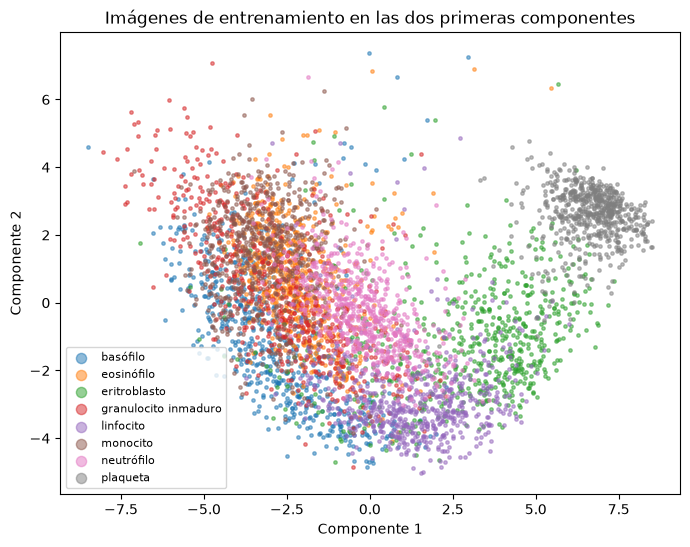

In [22]:
pca_2 = PCA(n_components=2, random_state=SEMILLA).fit(X_entr)
proyeccion = pca_2.transform(X_entr)
print("Varianza explicada por cada componente:", pca_2.explained_variance_ratio_.round(3))

fig, eje = plt.subplots(figsize=(8, 6))
for tipo, nombre in enumerate(TIPOS_CELULARES):
    de_este_tipo = y_entr == tipo
    eje.scatter(proyeccion[de_este_tipo, 0], proyeccion[de_este_tipo, 1], s=6, alpha=0.5, label=nombre)
eje.set(title="Imágenes de entrenamiento en las dos primeras componentes", xlabel="Componente 1", ylabel="Componente 2")
eje.legend(markerscale=3, fontsize=8)
plt.show()

#### Consigna 4.1 · Verificación: ¿cuántas componentes hacen falta?

Calculá la varianza explicada **acumulada** con hasta 200 componentes y graficala. Mirando **solo el gráfico**, anotá cuántas componentes hacen falta para explicar el 80 % y el 90 % de la varianza. Después pedí que se calcule.

**Se espera:** un gráfico de la varianza acumulada en función de la cantidad de componentes, con líneas horizontales en 0,8 y 0,9, y los dos números calculados. Tu lectura y el cálculo deberían diferir en pocas componentes.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

PCA guarda la fracción de varianza que explica cada componente; la acumulada es la suma acumulada de esas fracciones.

</details>

**Tu prompt:**

*...*

In [23]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 4.2 · Ablación del color

Convertí las imágenes a escala de grises (el promedio de los tres canales de cada píxel), mostrá algunas y entrená una regresión logística como la del bloque 1 con ellas.

**Se espera:** una grilla con las mismas imágenes de la consigna 1.1 en gris (una por tipo celular basta) y el F1 macro de prueba de la regresión logística en gris, comparado con el de color. Mirando las imágenes: ¿qué información se pierde?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

El promedio de los tres canales se calcula sobre el último eje de las imágenes. Después hay que aplanar y estandarizar como en el bloque 1, ahora con 784 columnas en lugar de 2352.

</details>

**Tu prompt:**

*...*

In [24]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 4.3 · Ablación de componentes

En lugar de darle a la regresión logística los 2352 valores de cada imagen, dale solo las primeras componentes principales. Probá con cada cantidad de `COMPONENTES`.

**Se espera:** una tabla `tabla_ablacion` con el F1 macro de prueba de la regresión logística en cada versión: con todas las columnas en color (bloque 1), en gris (consigna 4.2) y con cada cantidad de componentes principales. ¿Con cuántas componentes se recupera casi todo el F1?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Se pueden encadenar los pasos en un *pipeline*: primero PCA con la cantidad de componentes, después la regresión logística. Igual que el estandarizador, PCA se ajusta solo con los datos de entrenamiento.

</details>

**Tu prompt:**

*...*

In [25]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

## Bloque 5 · Agrupamiento con K-Means

**Producto:** dos tablas de grupos frente a tipos celulares y una conclusión.

Hasta ahora, los modelos aprendieron **con** las etiquetas. **K-Means** no las usa: reparte las imágenes en *k* grupos de modo que cada imagen quede cerca del centro de su grupo. Recién al final comparamos los grupos con los tipos celulares, para ver si el agrupamiento «descubrió» algo que coincide con lo que definieron los patólogos.

Para medir esa coincidencia usamos el **índice de Rand ajustado (ARI)**: vale 0 si los grupos no tienen nada que ver con los tipos celulares (como si se hubieran repartido al azar) y 1 si coinciden exactamente.

Primero probamos con **4 tipos celulares bien distintos entre sí**; después, con los 8.

**Ejemplo resuelto.** Las imágenes de los 4 tipos contrastados (2500 de la submuestra), resumidas en `COMPONENTES_AGRUPAMIENTO` componentes principales. K-Means trabaja sobre esas componentes: es más rápido y descarta parte del ruido. Como en el bloque 4, no hace falta estandarizar.

In [26]:
codigos_contrastados = [TIPOS_CELULARES.index(nombre) for nombre in TIPOS_CELULARES if nombre in TIPOS_CONTRASTADOS]
seleccion_4 = np.isin(y_entr, codigos_contrastados)
X_4 = X_entr[seleccion_4]
y_4 = y_entr[seleccion_4]
imagenes_4 = imagenes_entr[seleccion_4]

componentes_4 = PCA(n_components=COMPONENTES_AGRUPAMIENTO, random_state=SEMILLA).fit_transform(X_4)
print(f"Imágenes de {', '.join(TIPOS_CONTRASTADOS)}: {len(y_4)}")

Imágenes de linfocito, monocito, neutrófilo, plaqueta: 2500


#### Consigna 5.1 · Cuatro grupos para cuatro tipos celulares

Agrupá `componentes_4` en 4 grupos con K-Means y compará los grupos con los tipos celulares.

**Se espera:** una tabla cruzada con una fila por tipo celular y una columna por grupo (cuántas imágenes de cada tipo cayeron en cada grupo), y el ARI. Si el agrupamiento coincide con los tipos, cada fila tiene casi todas sus imágenes en una sola columna.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

K-Means está en scikit-learn; conviene fijar la semilla y pedirle varias inicializaciones. pandas tiene una función para armar tablas cruzadas. El ARI está en `sklearn.metrics`.

</details>

**Tu prompt:**

*...*

In [27]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 5.2 · Verificación: mirar los grupos

Un grupo es un conjunto de imágenes: hay que mirarlas. Mostrá 8 imágenes de cada grupo, elegidas al azar con la semilla.

**Se espera:** una grilla de 4 filas (una por grupo). ¿Cada fila se ve homogénea? ¿Coincide con lo que dice la tabla cruzada?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Para cada grupo, elegí 8 imágenes al azar entre las que tienen ese número de grupo, y pasalas a `mostrar_imagenes` con el número de grupo como título.

</details>

**Tu prompt:**

*...*

In [28]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 5.3 · ¿Cuántos grupos elegiría K-Means solo?

En la vida real no sabemos cuántos grupos hay. Dos criterios habituales: el **método del codo** (la inercia, es decir la distancia total de las imágenes al centro de su grupo, deja de bajar mucho a partir de cierto *k*) y la **silueta** (mide si cada imagen está más cerca de su grupo que del grupo vecino; cuanto mayor, mejor).

Calculá los dos para *k* entre 2 y `K_MAXIMO`, con las imágenes de los 4 tipos.

**Se espera:** dos gráficos, inercia y silueta en función de *k*. ¿Alguno de los dos señala claramente *k* = 4?

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Es un ciclo sobre *k*: para cada valor, un K-Means nuevo. La inercia queda guardada en el modelo; la silueta está en `sklearn.metrics`.

</details>

**Tu prompt:**

*...*

In [29]:
# Pegá o escribí aquí el código que generó el asistente


#### Consigna 5.4 · Ahora con los 8 tipos celulares

Repetí el agrupamiento con **toda** la submuestra (los 8 tipos, 5000 imágenes): resumila en `COMPONENTES_AGRUPAMIENTO` componentes principales, agrupala en 8 grupos y comparala con los tipos celulares.

**Se espera:** la tabla cruzada de 8 × 8 y el ARI, comparado con el de los 4 tipos. ¿Qué tipos celulares siguen formando su propio grupo y cuáles se mezclan? Mostrá 8 imágenes de un grupo mezclado para ver por qué.

<details>
<summary><b>¿Te trabaste?</b> (clic para ver una pista)</summary>

Son los mismos pasos que en el ejemplo resuelto y en las consignas 5.1 y 5.2, pero con `X_entr`, `y_entr` e `imagenes_entr`.

</details>

**Tu prompt:**

*...*

In [30]:
# Pegá o escribí aquí el código que generó el asistente


#### Tu interpretación

*...*

## Cierre

**Producto:** el cuaderno completo y guardado.

**Ejemplo resuelto.** Todos los modelos de clasificación de la clase, con su F1 macro.

In [31]:
tabla_modelos = pd.DataFrame(resultados).set_index("modelo")
tabla_modelos["diferencia"] = tabla_modelos["F1 entrenamiento"] - tabla_modelos["F1 prueba"]
tabla_modelos.sort_values("F1 prueba", ascending=False).round(3)

,F1 entrenamiento,F1 prueba,diferencia
modelo,,,
"red (100,), 40 épocas",1.0,0.793,0.207
árbol sin límite,1.0,0.574,0.426


#### Consigna final · Elegir y justificar un modelo

1. Pedile al asistente que explique, en lenguaje sencillo, la tabla `tabla_modelos` y que recomiende un modelo para clasificar estas imágenes.
2. **Verificá** la explicación contra la tabla: ¿cita bien los números? ¿Elige por el F1 de prueba y no por el de entrenamiento? ¿Tiene en cuenta la columna «diferencia»?
3. Escribí tu elección y justificala en tres o cuatro frases: qué métrica usaste, sobre qué datos, qué tiene de bueno o de malo el modelo y qué te dijo el bloque 5 sobre la dificultad de distinguir algunos tipos celulares.

**Tu elección y justificación:**

*...*